# Experiment 15 — allocation candidates versus deployed v11

Based on [NB14](14-backtest-profitable-allocation.ipynb). Compare **A**, the four-input score with original 90-day inverse variance; **C**, its regularised variance challenger; **G**, its downside-risk challenger; and the deployed **hyper-ai-v11.py** source rules.

The goal is to determine whether the research ranking and sizing changes improve net profit, CAGR and risk relative to deployed v11. Run every strategy with fresh $150,000 capital over **2026-01-01 → 2026-10-05 exclusive** and **2023-03-01 → 2026-10-08 exclusive**, retaining all available indicator warmup. The full-history final archive day is partial. Keep each strategy's existing logic, use NB14's repaired data and shared as-of-observation NAV pricing, and reproduce A/C/G before interpreting the comparison.

2026 results appear first. Full-history tables and charts are explicitly labelled. Every chart is a separate image with its own subheading, explanation and backtesting dates.

<!-- Results -->

## Summary of results

### 2026-01-01 → 2026-10-05 exclusive (through 4 October, UTC)

| Strategy | Net profit | CAGR | Sharpe | Max drawdown |
|:--|--:|--:|--:|--:|
| V11 | $44,521 | 41.20% | 1.96 | -6.40% |
| A | $55,430 | 51.77% | 2.30 | -6.35% |
| C | $51,111 | 47.56% | 2.12 | -6.93% |
| G | $50,819 | 47.28% | 2.11 | -7.72% |

### 2023-03-01 → 2026-10-08 exclusive (through 7 October, UTC; final archive day partial)

| Strategy | Net profit | CAGR | Sharpe | Max drawdown |
|:--|--:|--:|--:|--:|
| V11 | $108,947 | 16.35% | 1.28 | -7.92% |
| A | $162,108 | 22.53% | 1.65 | -7.92% |
| C | $210,443 | 27.53% | 1.56 | -10.73% |
| G | $213,794 | 27.85% | 1.54 | -11.37% |

## Key new insights

- **2026:** A has the highest profit ($55,430), with 51.77% CAGR, 2.30 Sharpe and -6.35% maximum drawdown.
  - A versus V11: profit $+10,909; CAGR +10.57 percentage points; Sharpe +0.34; drawdown +0.06 percentage points.
  - C versus A: profit $-4,319; CAGR -4.21 percentage points; Sharpe -0.18; drawdown -0.58 percentage points.
  - G versus C: profit $-292; CAGR -0.28 percentage points; Sharpe -0.01; drawdown -0.79 percentage points.
- **Full history:** G has the highest profit ($213,794), with 27.85% CAGR, 1.54 Sharpe and -11.37% maximum drawdown.
  - A versus V11: profit $+53,161; CAGR +6.18 percentage points; Sharpe +0.37; drawdown +0.00 percentage points.
  - C versus A: profit $+48,335; CAGR +4.99 percentage points; Sharpe -0.09; drawdown -2.82 percentage points.
  - G versus C: profit $+3,352; CAGR +0.33 percentage points; Sharpe -0.02; drawdown -0.64 percentage points.

A versus V11 changes the ranking formula with source sizing held fixed. C versus A changes a risk-estimation package, including partial-history support and filling, so its advantage cannot be attributed to shrinkage alone. G versus C changes the downside functional and its peer prior. These are historical comparisons, not independent statistical confirmation.

## Robustness of results

All eight accounts reconcile asset weights to equity and position profit to net account profit. A/C/G reproduce NB14 metrics under the shared NAV timing convention. Every successful vault fill matches an observation at or before its query, after undoing the inherited partial-trim fee adjustment for the timing check. Maximum positions remain six.

The full-history results include young vaults, sparse observations, empty-universe cash periods and previously searched years. Current universe/guard membership is retrospective. No quote-freshness veto is imposed. The inherited partial-trim fee issue and assumed redemption allowance remain material limitations.

Across the eight accounts, the largest single account update is 13.57%; the largest positive-profit concentration in one vault is 44.8%. The tables below attribute the strongest updates to actual NAV intervals and market context.

## Strategy logic comparison

This table describes the rules replayed in both periods. A is the research benchmark; v11 is the deployed strategy's source configuration. The historical simulation uses the shared repaired archive and current frozen universe/guard, rather than a replay of recorded live decisions.

| Strategy | Ranking and score | Position sizing | Parent and change | Missing and sparse history |
|:--|:--|:--|:--|:--|
| **V11: deployed rules** | 60% 360-day CAGR + 40% 45-day Sortino. CAGR is clipped to 0–100% and Sortino to 0–3; each component is mapped to 0–1. | Original inverse variance, using the source 90-day volatility indicator. | Source `hyper-ai-v11.py` decision callback and parameters, apart from the two replay date ranges. The existing local edit only relaxes a backtest floating-point assertion. | Missing composite scores become zero in source selection; eligible unscored vaults can still enter through the normal ranking. Source risk fallback is retained. |
| **A: research benchmark** | 48% 360-day CAGR + 32% 45-day Sortino + 10% 180-day CAGR + 10% 30-day Sortino. Same clips as v11. | Original source 90-day inverse variance, exactly as v11. | NB14 A: changes the ranking formula from v11 while retaining source sizing and the original allocator. | `missing=True`: retain the source unscored-entry behaviour; do not invent a score for unavailable active components. Source risk fallback is retained. |
| **C: historical challenger** | Same four-input score as A. | Inverse regularised 90-day variance: empirical variance is blended with a positive leave-one-out peer median. Empirical weight is `m / (m + 30)`, where `m` counts actual daily observation updates. | NB14 C, derived from A: changes the risk estimator package while retaining the original allocator. | Causal daily NAV forward filling starts at the first observation. Partial histories are allowed; actual updates determine confidence. Missing risk uses peer support; an unusable basket forecast falls back to equal sizing. |
| **G: downside challenger** | Same four-input score as A. | Inverse regularised 90-day downside moment: mean squared negative returns, including zero contributions from non-negative days. Uses the same observation-count shrinkage. | NB14 G, derived from C: replaces individual and peer total variance with downside risk. | Same partial-history support as C. A loss-free vault receives positive peer risk where available; use total-variance peer support if downside support is unavailable, then the existing basket fallback. |

### Shared portfolio and execution rules

Every strategy uses a six-position limit, two-day decisions, entry rank 6, incumbent exit rank 8, a 98% deployment target, 33% concentration and pool-size caps, $7,500 minimum TVL and a 14-day return gate above −16%. Source deposit/redemption permissions, guard checks, leader-share policy, rank hysteresis and trade thresholds are retained. There is no additional dollar-cap allocator or quote-freshness veto in this comparison.

New capital is blocked when observed leader share is below 5.5%. The source buy and sell thresholds start at $75 and $750 respectively for the $150,000 account, with the source equity-scaling behaviour retained. Redemption modelling retains 10% of positive realised profit plus a 0.1% gross redemption allowance; this allowance is an assumption, not a verified venue fee. No additional vault slippage is imposed.

All strategies use NAV observations timestamped at or before each price query, and indicators from completed prior daily buckets. This NB14 timing convention is shared by v11 as well: it is a research execution model, not a change to v11's live trading rules. Last-known NAV does not establish the actual executable NAV during an archive gap. The inherited partial-trim fee calculation can apply a fee twice and is retained for comparison; differing turnover can affect its impact.


In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'allocation_comparison.py').exists():
    ROOT=ROOT/'scratchpad/hyperliquid-vov-2nd'
sys.path.insert(0,str(ROOT))
from allocation_comparison import initialise,run,report
from score_matrix_visualisation import compact_output


## Load the common research environment

Pin the repaired archive, all pre-decision history, source strategy, guard and framework fingerprints. Reuse NB14's timing audit to set the common NAV convention. The v11 control retains its original score, sizing and source decision callback.

In [2]:
with compact_output('Pinned environment and cached NB14 timing controls; estimated 2–4 minutes'):
    data,evaluator=initialise()


Pinned environment and cached NB14 timing controls; estimated 2–4 minutes — complete

## Execute four strategies over two periods

Eight independent full-engine backtests, each starting from $150,000. Check A/C/G against NB14 and reconcile successful fill timestamps, position counts, asset weights and profit. The long run carries its own portfolio through 2026; its final year is not the same account as the separate fresh-start 2026 backtest.

In [3]:
with compact_output('Four strategies × two periods; estimated 4–12 minutes'):
    results,runs,attribution,absolute_weights=run(data,evaluator)


Four strategies × two periods; estimated 4–12 minutes — complete

## Compare returns, deployment and robustness

Tables show strategies side by side. Separate period sections include equity curves, quarterly returns, absolute asset weights and vault attribution for the largest account updates. BTC/ETH reference returns use the same actual NAV observation intervals.

In [4]:
with compact_output('Saved-state attribution and chart rendering; estimated 1–2 minutes'):
    findings=report(data,results,runs,attribution,absolute_weights)


Saved-state attribution and chart rendering; estimated 1–2 minutes — complete

## 2026 comparison

Fresh $150,000 accounts for 2026-01-01 → 2026-10-05 exclusive (through 4 October, UTC). A, C and G reproduce NB14; v11 uses its own source ranking and sizing.

### Key metrics — 2026-01-01 → 2026-10-05 exclusive (through 4 October, UTC)

Compare net economic outcomes in the same table. Green indicates the better value within each row. A is the benchmark; V11 is the deployed-rule control. Calmar is CAGR divided by absolute maximum drawdown.

Arm,V11,A,C,G
Final equity (USD),"$194,521","$205,430","$201,111","$200,819"
Net profit (USD),"$44,521","$55,430","$51,111","$50,819"
Cumulative return,29.68%,36.95%,34.07%,33.88%
CAGR,41.20%,51.77%,47.56%,47.28%
Sharpe,1.96,2.30,2.12,2.11
Sortino,3.43,4.13,3.68,3.67
Calmar,6.43,8.16,6.87,6.12
Maximum drawdown,-6.40%,-6.35%,-6.93%,-7.72%


### Deployment and trading — 2026-01-01 → 2026-10-05 exclusive (through 4 October, UTC)

Cash and turnover explain implementation differences. Recorded redemption costs are the inherited source estimate, not independently reconciled total fees. Cash includes early empty-universe periods in the full-history account. The 33% cap applies when allocating deployable capital; subsequent value drift can produce a higher observed equity weight.

...

### Concentration and extreme updates — 2023-03-01 → 2026-10-08 exclusive (through 7 October, UTC; final archive day partial)

Largest daily account updates may incorporate several days of sparse NAV changes. Positive profit share is the largest vault contribution divided by the sum of positive vault contributions, before subtracting losing vaults.

Arm,Best update,Excess kurtosis,Top positive profit share,Top_vault,Best_date,PnL residual (USD)
V11,5.33%,38.39,16.8%,Realist Capital,2025-08-14,$-0.000000
A,6.62%,37.32,15.4%,Realist Capital,2025-08-14,$-0.000000
C,13.02%,76.45,20.1%,Delta_01,2024-11-13,$-0.000000
G,13.57%,80.23,20.2%,Delta_01,2024-11-13,$0.000000


### Vault contributions behind the strongest updates — 2023-03-01 → 2026-10-08 exclusive (through 7 October, UTC; final archive day partial)

The three largest vault contributions on each strategy’s best account update. NAV returns and BTC/ETH context use the actual observation interval, which may span a week. Curator flags identify existing exclusions or quarantine; a large return alone does not establish a data error.

Arm,Update,Vault,Update profit (USD),NAV_return,Interval_days,Excluded,Quarantined,BTCUSDT return,ETHUSDT return
V11,2025-08-14,DailyTradeAI Low risk,"$3,612",+7.18%,7.03,False,False,+7.23%,+28.94%
V11,2025-08-14,cDOGE,"$3,164",+15.85%,6.97,False,False,+7.23%,+28.94%
V11,2025-08-14,JizzJazz,"$1,821",+11.41%,7.93,False,False,+7.23%,+28.94%
A,2025-08-14,naze oppa degen nation,"$4,406",+8.70%,7.00,False,False,+7.23%,+28.94%
A,2025-08-14,DailyTradeAI Low risk,"$3,612",+7.18%,7.03,False,False,+7.23%,+28.94%
A,2025-08-14,cDOGE,"$3,026",+15.85%,6.97,False,False,+7.23%,+28.94%
C,2024-11-13,Road to 10 Million,"$15,155",+30.26%,7.00,False,False,+19.59%,+17.09%
C,2024-11-13,FFLGN,"$4,326",+41.69%,6.07,False,False,+19.59%,+17.09%
C,2024-11-13,Delta_01,"$2,782",+7.26%,6.09,False,False,+19.59%,+17.09%
G,2024-11-13,Road to 10 Million,"$15,071",+30.26%,7.00,False,False,+19.59%,+17.09%


## Summary of results

### 2026-01-01 → 2026-10-05 exclusive (through 4 October, UTC)

| Strategy | Net profit | CAGR | Sharpe | Max drawdown |
|:--|--:|--:|--:|--:|
| V11 | $44,521 | 41.20% | 1.96 | -6.40% |
| A | $55,430 | 51.77% | 2.30 | -6.35% |
| C | $51,111 | 47.56% | 2.12 | -6.93% |
| G | $50,819 | 47.28% | 2.11 | -7.72% |

### 2023-03-01 → 2026-10-08 exclusive (through 7 October, UTC; final archive day partial)

| Strategy | Net profit | CAGR | Sharpe | Max drawdown |
|:--|--:|--:|--:|--:|
| V11 | $108,947 | 16.35% | 1.28 | -7.92% |
| A | $162,108 | 22.53% | 1.65 | -7.92% |
| C | $210,443 | 27.53% | 1.56 | -10.73% |
| G | $213,794 | 27.85% | 1.54 | -11.37% |

## Key new insights

- **2026:** A has the highest profit ($55,430), with 51.77% CAGR, 2.30 Sharpe and -6.35% maximum drawdown.
  - A versus V11: profit $+10,909; CAGR +10.57 percentage points; Sharpe +0.34; drawdown +0.06 percentage points.
  - C versus A: profit $-4,319; CAGR -4.21 percentage points; Sharpe -0.18; drawdown -0.58 percentage points.
  - G versus C: profit $-292; CAGR -0.28 percentage points; Sharpe -0.01; drawdown -0.79 percentage points.
- **Full history:** G has the highest profit ($213,794), with 27.85% CAGR, 1.54 Sharpe and -11.37% maximum drawdown.
  - A versus V11: profit $+53,161; CAGR +6.18 percentage points; Sharpe +0.37; drawdown +0.00 percentage points.
  - C versus A: profit $+48,335; CAGR +4.99 percentage points; Sharpe -0.09; drawdown -2.82 percentage points.
  - G versus C: profit $+3,352; CAGR +0.33 percentage points; Sharpe -0.02; drawdown -0.64 percentage points.

A versus V11 changes the ranking formula with source sizing held fixed. C versus A changes a risk-estimation package, including partial-history support and filling, so its advantage cannot be attributed to shrinkage alone. G versus C changes the downside functional and its peer prior. These are historical comparisons, not independent statistical confirmation.

## Robustness of results

All eight accounts reconcile asset weights to equity and position profit to net account profit. A/C/G reproduce NB14 metrics under the shared NAV timing convention. Every successful vault fill matches an observation at or before its query, after undoing the inherited partial-trim fee adjustment for the timing check. Maximum positions remain six.

The full-history results include young vaults, sparse observations, empty-universe cash periods and previously searched years. Current universe/guard membership is retrospective. No quote-freshness veto is imposed. The inherited partial-trim fee issue and assumed redemption allowance remain material limitations.

Across the eight accounts, the largest single account update is 13.57%; the largest positive-profit concentration in one vault is 44.8%. The tables below attribute the strongest updates to actual NAV intervals and market context.

### Interpretation of the comparison

A versus v11 improves both periods with source sizing held fixed: the four-input ranking earns about $10,909 more in fresh 2026 and $53,161 more over full history. Its 2026 Sharpe rises from 1.96 to 2.30, with slightly smaller drawdown; full-history Sharpe rises from 1.28 to 1.65 with the same −7.92% maximum drawdown. This is the clearest favourable comparison in this notebook.

C and G improve full-history CAGR further, but lose to A in fresh 2026. Their long gain is concentrated in earlier years: 2024 Q4 returns are approximately 47.2% for C and 48.1% for G, versus 17.0% for A. The biggest long-run updates are 13.02% and 13.57%, compared with A’s 6.62%. Several NAV marks span roughly a week; the underlying BTC/ETH interval returns are about +19.6%/+17.1%. Road to 10 Million supplies the largest contribution on that update, alongside FFLGN and Delta_01. The observations support the recorded movement, while actual executable NAV during sparse intervals remains uncertain.

Retain A as the current-period research benchmark and C as the main historical sizing challenger. G earns only $3,352 more than C over full history, with larger drawdown. These comparisons justify a frozen subsequent-period evaluation; the already searched history does not establish a production replacement.


## September 2026 cash investigation

### Actual cash balances — 2026-01-01 through 2026-10-04 backtest, September focus

These are daily USDC balances as a fraction of total account equity. The lighter grey region in the asset-weight charts is cash; the darker grey region is invested in other vaults.

| Strategy | September mean cash | Peak cash | 30 September cash |
|:--|--:|--:|--:|
| V11 | 41.6% | 72.8% | 58.2% |
| A | 49.1% | 74.0% | 60.5% |
| C | 48.7% | 73.4% | 59.6% |
| G | 48.8% | 73.3% | 59.5% |

### Why the cash increased

The ranking selects six vaults without considering whether their combined position capacity can absorb the account. The source allocator then limits each target to both 33% of the deployable account budget and 33% of that vault’s TVL. Lower-ranked vaults cannot fill the gap: `max_capacity_assets = max_assets_in_portfolio = 6` disables the residual-capacity extension.

In A, Citadel leaves on 4 September and AceVault Hyper01 on 8 September. They return on 14 and 12 September respectively, reducing cash. Citadel leaves again on 18 September; AceVault Hyper01 and Octavious Maximus leave on 20 September. The last two are replaced by Buyback Spread Engine and Sequoia HyperStable Yield Optimizer. The archived score changes explain these rotations; the removed vaults pass the −16% return gate on the inspected dates.

Across September’s 15 decision cycles, **96.9% of the sum of A’s planned deployment shortfalls** comes from the combined concentration/TVL ceiling, 2.6% from rejected top-ups and 0.5% from allocation below the feasible ceiling. This sums repeated decision-level shortfalls, not lost profit or distinct cash dollars.

### Concrete example — decision on 20 September 2026

A has a $194,853 deployable budget. The six selected vaults have combined TVL of approximately $219,878; their 33%-of-TVL limits admit only $72,560 in total. All six targets reach their TVL limits before admission checks. The table shows target dollars, not new deposit requests.

| Selected vault | TVL | Target before admission | Final target |
|:--|--:|--:|--:|
| HYPErQuantum4 | $24,597 | $8,117 | $7,810 |
| Gucky_4coin_2dot5x | $13,875 | $4,579 | $3,532 |
| Mad Scientists | $52,495 | $17,323 | $17,323 |
| Buyback Spread Engine | $20,968 | $6,919 | $6,919 |
| Sequoia HyperStable Yield Optimizer | $16,161 | $5,333 | $5,333 |
| DOEZOE | $91,783 | $30,288 | $30,288 |

Pool limits leave **$122,293** of the deployable budget unused. HYPErQuantum4 and Gucky_4coin_2dot5x then reject **$1,354** of additional top-ups, leaving a $71,206 final target basket. Together with the approximately $3,977 deployment reserve, this predicts about **$127,624 cash**, matching the saved post-trade wallet balance. Cash is 64.2% of marked equity on that day.

### Deposit checks and other explanations

The inspected HYPErQuantum4 and Gucky_4coin_2dot5x rows have fresh previous-day permission observations, open-deposit flags and archived zero deposit caps; leader shares are approximately 5.38% and 5.19% on 20 September, below the strategy’s 5.5% policy. These checks reject top-ups rather than close the existing positions. DOEZOE is open on 20 September, then reports deposits disabled by its leader from the 22 September decision onward. By 30 September, rejected top-ups total $8,436; the concentration/TVL shortfall is still much larger, at $109,774.

No pending redemptions or pinned settlement capital are recorded on any September decision in these four accounts. This comparison imposes no extra NAV-freshness veto. The inspected rejected checks use known recent observations rather than an unknown/stale permission clock. The 2% deployment reserve and trade thresholds cannot explain cash above 60%.

By 20 September, all four strategies target the same $71,206 basket despite their different variance estimators and account sizes. Different weights cannot overcome the aggregate TVL ceiling; A’s larger capital also produces a higher cash percentage under the same absolute vault limits.

### Cash and allocation shortfalls — 2026-01-01 through 2026-10-04 backtest, September focus

Bars split the unallocated target budget into cap constraints, allocator slack and blocked top-ups. The line is actual wallet cash after trades, which also includes the deployment reserve and trade/accounting differences. Each bar is a separate decision snapshot, not a cumulative loss.

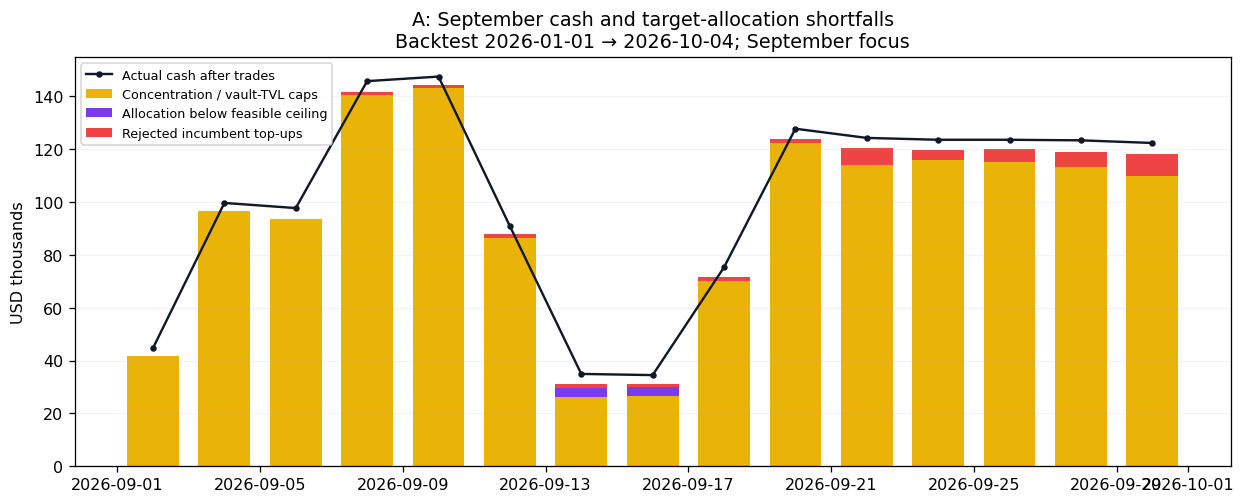

### Implication

September is mainly a basket-capacity problem. A useful next comparison would let selection account for usable capacity, or retain a larger incumbent when a proposed replacement contributes little deployable capital. Increasing the number of positions or relaxing TVL caps are other possible interventions, but should be judged by net profit and risk: filling cash with lower-quality vaults need not improve returns.